# Understanding the decision tree structure: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/tree/plot_unveil_tree_structure.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/tree/plot_unveil_tree_structure.html)).

**Scenario:** `DecisionTreeClassifier(max_leaf_nodes=3, random_state=0)` on the iris training split
(best-first growth), then the low-level tree structure (`children_left/right`, `feature`,
`threshold`, `value`, node depths, leaves), `plot_tree(clf, proportion=True)`, `apply`, and
`decision_path` for the rules of one sample and the nodes shared by two samples. Extra checks
compare `export_graphviz`, `export_text`, `get_depth`, `get_n_leaves`, `feature_importances_`
and the `tree_` node statistics.

**Adaptations:**
- Bundled iris data; labels are integers, so Moxie uses `DecisionTreeClassifier[DType.int64]`.
  Features are shared as Float32, the dtype sklearn converts to inside `fit`.
- `tree_` is Moxie's native `TreeData` record: per-node `Node` structs in `tree_.nodes`
  (`left_child`, `right_child`, `feature`, `threshold`, `impurity`, `n_node_samples`,
  `weighted_n_node_samples`, `missing_go_to_left`) and an owned Float64
  `(node_count, n_outputs, max_n_classes)` `tree_.value` array, documented in `docs/tree/estimators.md`.
  The Mojo cell builds sklearn's parallel arrays from it. Leaves use `-1` children and feature `-1`;
  sklearn reports leaf feature `-2` and threshold `-2.0` (`TREE_UNDEFINED`), so those sentinels are mapped.
- `plot_tree` returns a standalone SVG string instead of Matplotlib artists (documented adaptation).
- `decision_path` is **not available**: it returns a CSR matrix in sklearn and Moxie excludes sparse
  output (`docs/tree/scope.md`). It is recorded as a GAP with an expect-fail cell. The rules and the
  shared nodes are reconstructed natively by walking `tree_.nodes` (user code, not a Moxie API) and
  compared with sklearn's indicator matrix.
- The Python cells use the scikit-learn wheel installed in the notebooks environment.

**Determinism:** deterministic (`random_state=0`, all features searched).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("tree/plot_unveil_tree_structure")

## 1. scikit-learn (Python reference)

The official example code; `plot_tree` uses a small figure.

The binary tree structure has 5 nodes and has the following tree structure:

node=0 is a split node with value=[[0.33  0.304 0.366]]: go to node 1 if X[:, 3] <= 0.800000011920929 else to node 2.
	node=1 is a leaf node with value=[[1. 0. 0.]].
	node=2 is a split node with value=[[0.    0.453 0.547]]: go to node 3 if X[:, 2] <= 4.950000047683716 else to node 4.
		node=3 is a leaf node with value=[[0.    0.917 0.083]].
		node=4 is a leaf node with value=[[0.    0.026 0.974]].


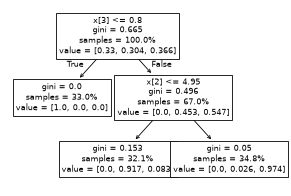

Rules used to predict sample 0:

decision node 0 : (X_test[0, 3] = 2.4) > 0.800000011920929)
decision node 2 : (X_test[0, 2] = 5.1) > 4.950000047683716)

The following samples [0, 1] share the node(s) [0 2] in the tree.
This is 40.0% of all nodes.


In [2]:
import numpy as np
from matplotlib import pyplot as plt

from sklearn import tree
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

iris = load_iris()
X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

clf = DecisionTreeClassifier(max_leaf_nodes=3, random_state=0)
clf.fit(X_train, y_train)

n_nodes = clf.tree_.node_count
children_left = clf.tree_.children_left
children_right = clf.tree_.children_right
feature = clf.tree_.feature
threshold = clf.tree_.threshold
values = clf.tree_.value

node_depth = np.zeros(shape=n_nodes, dtype=np.int64)
is_leaves = np.zeros(shape=n_nodes, dtype=bool)
stack = [(0, 0)]  # start with the root node id (0) and its depth (0)
while len(stack) > 0:
    node_id, depth = stack.pop()
    node_depth[node_id] = depth
    is_split_node = children_left[node_id] != children_right[node_id]
    if is_split_node:
        stack.append((children_left[node_id], depth + 1))
        stack.append((children_right[node_id], depth + 1))
    else:
        is_leaves[node_id] = True

print(
    "The binary tree structure has {n} nodes and has "
    "the following tree structure:\n".format(n=n_nodes)
)
for i in range(n_nodes):
    if is_leaves[i]:
        print(
            "{space}node={node} is a leaf node with value={value}.".format(
                space=node_depth[i] * "\t", node=i, value=np.around(values[i], 3)
            )
        )
    else:
        print(
            "{space}node={node} is a split node with value={value}: "
            "go to node {left} if X[:, {feature}] <= {threshold} "
            "else to node {right}.".format(
                space=node_depth[i] * "\t",
                node=i,
                left=children_left[i],
                feature=feature[i],
                threshold=threshold[i],
                right=children_right[i],
                value=np.around(values[i], 3),
            )
        )

plt.figure(figsize=(6, 4), dpi=60)
tree.plot_tree(clf, proportion=True)
plt.show()

node_indicator = clf.decision_path(X_test)
leaf_id = clf.apply(X_test)

sample_id = 0
node_index = node_indicator.indices[
    node_indicator.indptr[sample_id] : node_indicator.indptr[sample_id + 1]
]
print("Rules used to predict sample {id}:\n".format(id=sample_id))
for node_id in node_index:
    if leaf_id[sample_id] == node_id:
        continue
    if X_test[sample_id, feature[node_id]] <= threshold[node_id]:
        threshold_sign = "<="
    else:
        threshold_sign = ">"
    print(
        "decision node {node} : (X_test[{sample}, {feature}] = {value}) "
        "{inequality} {threshold})".format(
            node=node_id,
            sample=sample_id,
            feature=feature[node_id],
            value=X_test[sample_id, feature[node_id]],
            inequality=threshold_sign,
            threshold=threshold[node_id],
        )
    )

sample_ids = [0, 1]
common_nodes = node_indicator.toarray()[sample_ids].sum(axis=0) == len(sample_ids)
common_node_id = np.arange(n_nodes)[common_nodes]
print(
    "\nThe following samples {samples} share the node(s) {nodes} in the tree.".format(
        samples=sample_ids, nodes=common_node_id
    )
)
print("This is {prop}% of all nodes.".format(prop=100 * len(common_node_id) / n_nodes))

nb.share(X_train=X_train.astype(np.float32), y_train=y_train, X_test=X_test.astype(np.float32))

## 2. Moxie (native Mojo)

Fit, structure arrays, `apply`, exports and a native traversal standing in for `decision_path`.

In [3]:
%%mojo structure
import numojo as nm
from moxie.tree import DecisionTreeClassifier, export_graphviz, export_text, plot_tree
from moxie_nb_io import load, save, save_ints, save_floats, save_strings


def main() raises:
    var X_train = load[DType.float32]("X_train")
    var y_train = load[DType.int64]("y_train")
    var X_test = load[DType.float32]("X_test")

    var clf = DecisionTreeClassifier[DType.int64](max_leaf_nodes=3, random_state=0)
    _ = clf.fit(X_train, y_train)

    var n_nodes = clf.tree_.node_count
    var left = List[Int]()
    var right = List[Int]()
    var feature = List[Int]()
    var threshold = List[Float64]()
    var impurity = List[Float64]()
    var n_samples = List[Int]()
    var weighted = List[Float64]()
    for i in range(n_nodes):
        ref node = clf.tree_.nodes[i]
        left.append(node.left_child)
        right.append(node.right_child)
        # sklearn's TREE_UNDEFINED (-2) for leaf features/thresholds.
        feature.append(node.feature if node.left_child != -1 else -2)
        threshold.append(node.threshold if node.left_child != -1 else -2.0)
        impurity.append(node.impurity)
        n_samples.append(node.n_node_samples)
        weighted.append(node.weighted_n_node_samples)

    # The example's depth/leaf traversal, on the native node records.
    var node_depth = List[Int](length=n_nodes, fill=0)
    var is_leaf = List[Int](length=n_nodes, fill=0)
    var stack: List[Tuple[Int, Int]] = [(0, 0)]
    while len(stack) > 0:
        var top = stack.pop()
        node_depth[top[0]] = top[1]
        if left[top[0]] != right[top[0]]:
            stack.append((left[top[0]], top[1] + 1))
            stack.append((right[top[0]], top[1] + 1))
        else:
            is_leaf[top[0]] = 1
    print("The binary tree structure has", n_nodes, "nodes")
    for i in range(n_nodes):
        var space = String("")
        for _ in range(node_depth[i]):
            space += "\t"
        if is_leaf[i] == 1:
            print(space + "node=" + String(i) + " is a leaf node.")
        else:
            print(space + "node=" + String(i) + " is a split node: go to node " + String(left[i])
                  + " if X[:, " + String(feature[i]) + "] <= " + String(threshold[i])
                  + " else to node " + String(right[i]) + ".")

    var leaf_id = clf.apply(X_test)
    # Native replacement for the CSR decision_path: walk from the root with each sample.
    var m = X_test.shape[0]
    var indicator = nm.zeros[DType.int64](nm.Shape(m, n_nodes))
    for s in range(m):
        var node = 0
        while True:
            indicator.itemset([s, node], 1)
            if left[node] == -1:
                break
            var value = Float64(X_test.item(s, feature[node]))
            node = left[node] if value <= threshold[node] else right[node]

    save_ints("children_left", left)
    save_ints("children_right", right)
    save_ints("feature", feature)
    save_floats("threshold", threshold)
    save_floats("impurity", impurity)
    save_ints("n_node_samples", n_samples)
    save_floats("weighted_n_node_samples", weighted)
    save("value", clf.tree_.value)
    save_ints("node_depth", node_depth)
    save_ints("is_leaves", is_leaf)
    save("leaf_id", leaf_id)
    save("indicator", indicator)
    save("feature_importances", clf.feature_importances_)
    save_ints("depth_leaves", [clf.get_depth(), clf.get_n_leaves()])
    save("proba", clf.predict_proba(X_test)[0])
    save_strings("svg", [plot_tree(clf, proportion=True)])
    save_strings("dot", [export_graphviz(clf)])
    save_strings("text", [export_text(clf)])

The binary tree structure has 5 nodes
node=0 is a split node: go to node 1 if X[:, 3] <= 0.800000011920929 else to node 2.
	node=1 is a leaf node.
	node=2 is a split node: go to node 3 if X[:, 2] <= 4.950000047683716 else to node 4.
		node=3 is a leaf node.
		node=4 is a leaf node.


`decision_path` is absent from the native API (sparse output exclusion); this cell must fail to compile.

In [4]:
%%mojo decision_path --expect-fail
from moxie.tree import DecisionTreeClassifier
from moxie_nb_io import load


def main() raises:
    var clf = DecisionTreeClassifier[DType.int64](max_leaf_nodes=3, random_state=0)
    _ = clf.fit(load[DType.float32]("X_train"), load[DType.int64]("y_train"))
    _ = clf.decision_path(load[DType.float32]("X_test"))

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/tree/plot_unveil_tree_structure/decision_path.mojo:8:12: error: 'BaseDecisionTree[True, label_dtype=DType.int64]' value has no attribute 'decision_path'
    _ = clf.decision_path(load[DType.float32]("X_test"))
        ~~~^
mojo: error: failed to parse the provided Mojo source module



## 3. Side by side and parity

Moxie plot_tree(clf, proportion=True) (native SVG):


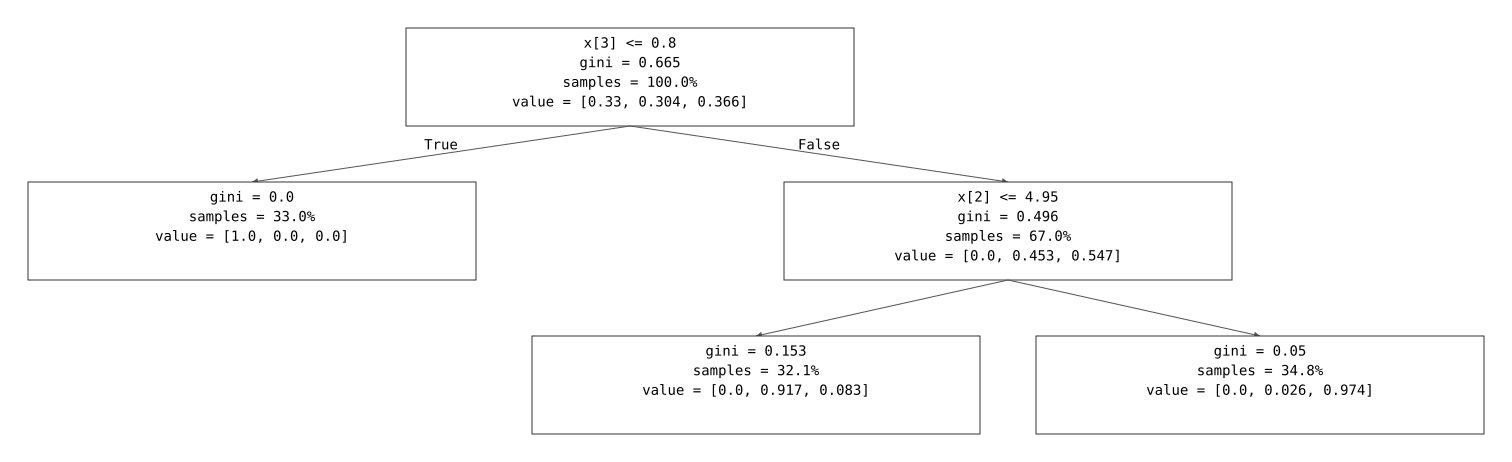

In [5]:
from IPython.display import SVG, display
from sklearn.tree import export_graphviz, export_text

mx = nb.results["structure"]
print("Moxie plot_tree(clf, proportion=True) (native SVG):")
display(SVG(str(mx["svg"][0])))
moxie_nb.side_by_side(sklearn=np.c_[children_left, children_right, feature, threshold],
                      moxie=np.c_[mx["children_left"], mx["children_right"], mx["feature"], mx["threshold"]])

nb.compare("tree_.children_left", children_left, mx["children_left"], exact=True)
nb.compare("tree_.children_right", children_right, mx["children_right"], exact=True)
nb.compare("tree_.feature", feature, mx["feature"], exact=True)
nb.compare("tree_.threshold", threshold, mx["threshold"], exact=True)
nb.compare("tree_.n_node_samples", clf.tree_.n_node_samples, mx["n_node_samples"], exact=True)
nb.compare("tree_.weighted_n_node_samples", clf.tree_.weighted_n_node_samples,
           mx["weighted_n_node_samples"], exact=True)
nb.compare("tree_.impurity", clf.tree_.impurity, mx["impurity"], rtol=2e-12, atol=2e-12,
           reason="Gini from identical Float64 weighted counts; 2e-12 covers summation roundoff "
                  "(family oracle bound)")
nb.compare("tree_.value", values, mx["value"], rtol=2e-12, atol=2e-12,
           reason="class fractions are one Float64 division of identical weighted counts")
nb.compare("node_depth", node_depth, mx["node_depth"], exact=True)
nb.compare("is_leaves", is_leaves, mx["is_leaves"].astype(bool), exact=True)
nb.compare("apply(X_test)", leaf_id, mx["leaf_id"], exact=True)
nb.compare("get_depth, get_n_leaves", [clf.get_depth(), clf.get_n_leaves()], mx["depth_leaves"], exact=True)
nb.compare("feature_importances_", clf.feature_importances_, mx["feature_importances"], rtol=2e-12, atol=2e-12,
           reason="normalized impurity decreases in Float64; summation roundoff only")
nb.compare("predict_proba(X_test)", clf.predict_proba(X_test), mx["proba"], rtol=1e-15, atol=1e-15,
           reason="leaf fractions copied from tree_.value")
nb.compare("export_graphviz(clf)", np.array([export_graphviz(clf)]), mx["dot"], exact=True)
nb.compare("export_text(clf)", np.array([export_text(clf)]), mx["text"], exact=True)
nb.compare("decision path rebuilt from tree_ (all test samples)", node_indicator.toarray(), mx["indicator"],
           exact=True)
mx_common = np.arange(n_nodes)[mx["indicator"][sample_ids].sum(axis=0) == len(sample_ids)]
nb.compare("nodes shared by samples [0, 1]", common_node_id, mx_common, exact=True)
nb.note("decision_path", "GAP",
        "sklearn returns a CSR node-indicator matrix; Moxie excludes sparse outputs "
        "(docs/tree/scope.md, ../session-plan/SPARSITY-SCOPE.md), so the method is absent and the "
        "expect-fail cell does not compile. The path above is rebuilt from tree_.nodes by user code.")
nb.note("plot_tree", "ADAPTED",
        "returns standalone SVG (shown above) instead of Matplotlib annotations; node labels and colors "
        "are checked against sklearn by tests/tree/export_graphviz_parity.py, pixel layout is not compared.")
nb.note("tree_ arrays", "ADAPTED",
        "native Node records plus a Float64 value array; leaf sentinels -1 (Moxie) vs -2 (sklearn) mapped above.")

In [6]:
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
tree_.children_left,PASS,"(5,)","(5,)",,,exact,0 mismatches,
tree_.children_right,PASS,"(5,)","(5,)",,,exact,0 mismatches,
tree_.feature,PASS,"(5,)","(5,)",,,exact,0 mismatches,
tree_.threshold,PASS,"(5,)","(5,)",,,exact,0 mismatches,
tree_.n_node_samples,PASS,"(5,)","(5,)",,,exact,0 mismatches,
tree_.weighted_n_node_samples,PASS,"(5,)","(5,)",,,exact,0 mismatches,
tree_.impurity,PASS,"(5,)","(5,)",0,0,"rtol=2e-12, atol=2e-12",,Gini from identical Float64 weighted counts; 2e-12 covers summation roundoff (family oracle bound)
tree_.value,PASS,"(5, 1, 3)","(5, 1, 3)",0,0,"rtol=2e-12, atol=2e-12",,class fractions are one Float64 division of identical weighted counts
node_depth,PASS,"(5,)","(5,)",,,exact,0 mismatches,
is_leaves,PASS,"(5,)","(5,)",,,exact,0 mismatches,
